<a href="https://colab.research.google.com/github/Ayan-Rony/LearningML/blob/main/mini_proj.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import tensorflow as tf
import os
import imageio
import matplotlib.pyplot as plt

from tensorflow.keras.layers import (
    Input, Conv2D, MaxPooling2D,
    Dropout, Conv2DTranspose, concatenate
)
from tensorflow.keras import Model
from google.colab import drive

In [ ]:
from termcolor import colored

def comparator(learner, instructor):
    if len(learner) != len(instructor):
        raise AssertionError("Layer count mismatch")
    for a, b in zip(learner, instructor):
        if tuple(a) != tuple(b):
            print(colored("Test failed", attrs=['bold']))
            raise AssertionError("Error in test")
    print(colored("All tests passed!", "green"))

def summary(model):
    result = []
    for layer in model.layers:
        output_shape = getattr(layer.output, 'shape', None)
        params = layer.count_params() if hasattr(layer, 'count_params') else 0
        result.append([layer.__class__.__name__, output_shape, params])
    return result

In [ ]:


image_path = "/content/drive/MyDrive/mini_project/miniproj/trainval-image"
mask_path  = "/content/drive/MyDrive/mini_project/miniproj/trainval-mask"

image_list = sorted([os.path.join(image_path, f) for f in os.listdir(image_path) if f.endswith('.jpg')])
mask_list  = sorted([os.path.join(mask_path, f) for f in os.listdir(mask_path) if f.endswith('.jpg')])


In [ ]:
print(f"Length of image_list: {len(image_list)}")
print(f"Length of mask_list: {len(mask_list)}")

Length of image_list: 2879
Length of mask_list: 2879


/tmp/ipykernel_2068/1568518156.py:8: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  img  = imageio.imread(image_list[N])
/tmp/ipykernel_2068/1568518156.py:9: DeprecationWarning: Starting with ImageIO v3 the behavior of this function will switch to that of iio.v3.imread. To keep the current behavior (and make this warning disappear) use `import imageio.v2 as imageio` or call `imageio.v2.imread` directly.
  mask = imageio.imread(mask_list[N])


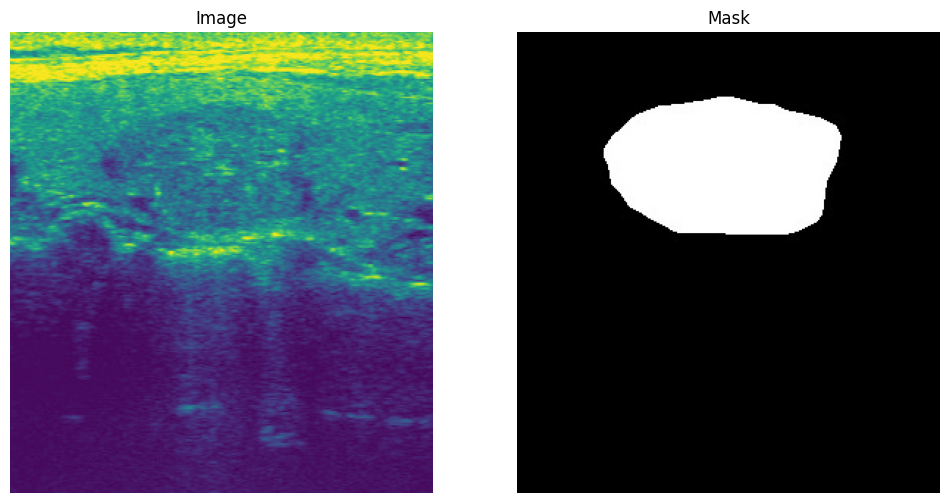

In [ ]:
N = min(2, len(image_list) - 1) if len(image_list) > 0 else 0

if len(image_list) == 0:
    print("Error: image_list is empty. Cannot display image and mask.")
elif N < 0:
    print(f"Error: Invalid index N={N}. Please ensure N is a non-negative integer.")
else:
    img  = imageio.imread(image_list[N])
    mask = imageio.imread(mask_list[N])

    fig, ax = plt.subplots(1, 2, figsize=(12, 6))
    ax[0].imshow(img)
    ax[0].set_title("Image")
    ax[0].axis("off")

    ax[1].imshow(mask[:, :, 0] if mask.ndim == 3 else mask, cmap="gray")
    ax[1].set_title("Mask")
    ax[1].axis("off")
    plt.show()

In [ ]:
!ls -l

total 8
drwx------ 5 root root 4096 Apr 27 18:38 drive
drwxr-xr-x 1 root root 4096 Apr 16 13:33 sample_data


In [ ]:
print(f"Length of image_list: {len(image_list)}")
print(f"Length of mask_list: {len(mask_list)}")

min_len = min(len(image_list), len(mask_list))
image_filenames = tf.constant(image_list[:min_len])
mask_filenames  = tf.constant(mask_list[:min_len])

dataset = tf.data.Dataset.from_tensor_slices((image_filenames, mask_filenames))
print(f"Dataset created successfully with {min_len} image-mask pairs.")


Length of image_list: 2879
Length of mask_list: 2879
Dataset created successfully with 2879 image-mask pairs.


In [ ]:
min_len = min(len(image_list), len(mask_list))
image_filenames = tf.constant(image_list[:min_len])
mask_filenames  = tf.constant(mask_list[:min_len])

dataset = tf.data.Dataset.from_tensor_slices((image_filenames, mask_filenames))
print(f"Dataset created successfully with {min_len} image-mask pairs.")

Dataset created successfully with 2879 image-mask pairs.


In [ ]:
def process_path(image_path, mask_path):
    img = tf.io.read_file(image_path)
    img = tf.image.decode_png(img, channels=3)
    img = tf.image.convert_image_dtype(img, tf.float32)

    mask = tf.io.read_file(mask_path)
    mask = tf.image.decode_png(mask, channels=3)
    mask = tf.math.reduce_max(mask, axis=-1, keepdims=True)
    return img, mask

def preprocess(image, mask):
    input_image = tf.image.resize(image, (96, 128), method='nearest')
    input_mask = tf.image.resize(mask, (96, 128), method='nearest')

    input_image = input_image / 255.

    # Ensure mask is integer type and values are within [0, n_classes-1]
    # n_classes is 23 as defined in unet_model
    n_classes_val = 23
    input_mask = tf.cast(input_mask, dtype=tf.int32)
    input_mask = tf.clip_by_value(input_mask, 0, n_classes_val - 1)

    return input_image, input_mask

image_ds = dataset.map(process_path)
processed_image_ds = image_ds.map(preprocess)

In [ ]:
def conv_block(inputs, n_filters, dropout_prob=0, max_pooling=True):
    conv = Conv2D(n_filters, 3, activation='relu', padding='same',
                  kernel_initializer='he_normal')(inputs)
    conv = Conv2D(n_filters, 3, activation='relu', padding='same',
                  kernel_initializer='he_normal')(conv)

    if dropout_prob > 0:
        conv = Dropout(dropout_prob)(conv)

    next_layer = MaxPooling2D((2, 2))(conv) if max_pooling else conv
    skip_connection = conv
    return next_layer, skip_connection
def upsampling_block(expansive_input, contractive_input, n_filters):
    up = Conv2DTranspose(n_filters, 3, strides=2, padding='same')(expansive_input)
    merge = concatenate([up, contractive_input], axis=3)

    conv = Conv2D(n_filters, 3, activation='relu', padding='same',
                  kernel_initializer='he_normal')(merge)
    conv = Conv2D(n_filters, 3, activation='relu', padding='same',
                  kernel_initializer='he_normal')(conv)
    return conv

In [ ]:
def unet_model(input_size=(96,128,3), n_filters=32, n_classes=23):
    inputs = Input(input_size)

    c1 = conv_block(inputs, n_filters)
    c2 = conv_block(c1[0], n_filters*2)
    c3 = conv_block(c2[0], n_filters*4)
    c4 = conv_block(c3[0], n_filters*8, dropout_prob=0.3)
    c5 = conv_block(c4[0], n_filters*16, dropout_prob=0.3, max_pooling=False)

    u6 = upsampling_block(c5[0], c4[1], n_filters*8)
    u7 = upsampling_block(u6, c3[1], n_filters*4)
    u8 = upsampling_block(u7, c2[1], n_filters*2)
    u9 = upsampling_block(u8, c1[1], n_filters)

    # Removed softmax activation from the output layer
    outputs = Conv2D(n_classes, 1)(u9)
    return Model(inputs, outputs)
unet = unet_model()
unet.compile(
    optimizer='adam',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)
unet.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 96, 128,   │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d (Conv2D)     │ (None, 96, 128,   │        896 │ input_layer[0][0] │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_1 (Conv2D)   │ (None, 96, 128,   │      9,248 │ conv2d[0][0]      │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d       │ (None, 48, 64,    │          0 │ conv2d_1[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_2 (Conv2D)   │ (None, 48, 64,    │     18,496 │ max_pooling2d[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_3 (Conv2D)   │ (None, 48, 64,    │     36,928 │ conv2d_2[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_1     │ (None, 24, 32,    │          0 │ conv2d_3[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_4 (Conv2D)   │ (None, 24, 32,    │     73,856 │ max_pooling2d_1[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_5 (Conv2D)   │ (None, 24, 32,    │    147,584 │ conv2d_4[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_2     │ (None, 12, 16,    │          0 │ conv2d_5[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_6 (Conv2D)   │ (None, 12, 16,    │    295,168 │ max_pooling2d_2[… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_7 (Conv2D)   │ (None, 12, 16,    │    590,080 │ conv2d_6[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 12, 16,    │          0 │ conv2d_7[0][0]    │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_3     │ (None, 6, 8, 256) │          0 │ dropout[0][0]     │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_8 (Conv2D)   │ (None, 6, 8, 512) │  1,180,160 │ max_pooling2d_3[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_9 (Conv2D)   │ (None, 6, 8, 512) │  2,359,808 │ conv2d_8[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 6, 8, 512) │          0 │ conv2d_9[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_transpose    │ (None, 12, 16,    │  1,179,904 │ dropout_1[0][0] 

 Total params: 8,631,223 (32.93 MB)

 Trainable params: 8,631,223 (32.93 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
for image_batch, mask_batch in processed_image_ds.take(1):
    print(f"Shape of image batch: {image_batch.shape}")
    print(f"Shape of mask batch: {mask_batch.shape}")
    print(f"Mask batch unique values: {tf.unique(tf.reshape(mask_batch, [-1])).y.numpy()}")
    print(f"Max value in mask batch: {tf.reduce_max(mask_batch).numpy()}")
    print(f"Min value in mask batch: {tf.reduce_min(mask_batch).numpy()}")

Shape of image batch: (96, 128, 3)
Shape of mask batch: (96, 128, 1)
Mask batch unique values: [ 0  1  2  7 22  9  5  6  8 10  3  4]
Max value in mask batch: 22
Min value in mask batch: 0


In [ ]:
EPOCHS = 40
VAL_SUBSPLITS = 5
BUFFER_SIZE = 500
BATCH_SIZE = 32
processed_image_ds.batch(BATCH_SIZE)
train_dataset = processed_image_ds.cache().shuffle(BUFFER_SIZE).batch(BATCH_SIZE)
print(processed_image_ds.element_spec)
model_history = unet.fit(train_dataset, epochs=EPOCHS)

(TensorSpec(shape=(96, 128, 3), dtype=tf.float32, name=None), TensorSpec(shape=(96, 128, 1), dtype=tf.int32, name=None))
Epoch 1/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 1264s 11s/step - accuracy: 0.7837 - loss: 1.1317
Epoch 2/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 12s 138ms/step - accuracy: 0.8513 - loss: 0.3863
Epoch 3/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 13s 140ms/step - accuracy: 0.8527 - loss: 0.3580
Epoch 4/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 13s 140ms/step - accuracy: 0.8902 - loss: 0.2995
Epoch 5/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 12s 138ms/step - accuracy: 0.8979 - loss: 0.2807
Epoch 6/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 12s 138ms/step - accuracy: 0.9014 - loss: 0.2713
Epoch 7/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 12s 137ms/step - accuracy: 0.9029 - loss: 0.2658
Epoch 8/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 12s 138ms/step - accuracy: 0.9059 - loss: 0.2579
Epoch 9/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 12s 139ms/step - accuracy: 0.9076 - loss: 0.2540
Epoch 10/40
90/90 ━━━━━━━━━━━━━━━━━━━━ 12s 139ms/step - accuracy: 0.9080 - loss: 0.2537
Epoch 11

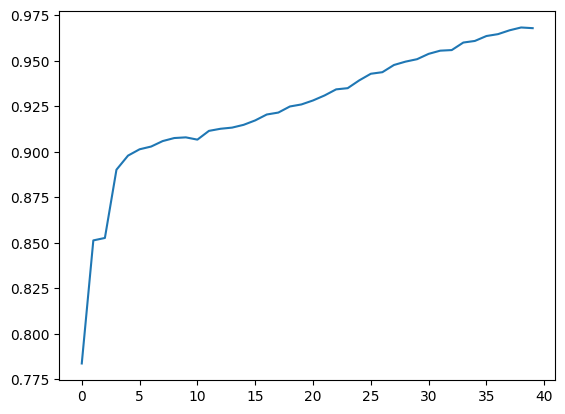

In [ ]:
plt.plot(model_history.history["accuracy"])

In [ ]:
def create_mask(pred_mask):
    pred_mask = tf.argmax(pred_mask, axis=-1)
    pred_mask = pred_mask[..., tf.newaxis]
    return pred_mask[0]
def show_predictions(dataset=None, num=1):
    if dataset:
        for image, mask in dataset.take(num):
            pred_mask = unet.predict(image)
            display([image[0], mask[0], create_mask(pred_mask)])
    else:
        display([sample_image, sample_mask,
             create_mask(unet.predict(sample_image[tf.newaxis, ...]))])

show_predictions(train_dataset, 6)

1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step


[<tf.Tensor: shape=(96, 128, 3), dtype=float32, numpy=
 array([[[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [1.84544420e-04, 1.84544420e-04, 1.84544420e-04],
         [6.76662836e-04, 6.76662836e-04, 6.76662836e-04],
         ...,
         [2.50672828e-03, 2.50672828e-03, 2.50672828e-03],
         [2.26066913e-03, 2.26066913e-03, 2.26066913e-03],
         [2.18377565e-03, 2.18377565e-03, 2.18377565e-03]],
 
        [[0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
         [9.22722102e-05, 9.22722102e-05, 9.22722102e-05],
         [2.76816631e-04, 2.76816631e-04, 2.76816631e-04],
         ...,
         [2.50672828e-03, 2.50672828e-03, 2.50672828e-03],
         [2.21453304e-03, 2.21453304e-03, 2.21453304e-03],
         [2.12226086e-03, 2.12226086e-03, 2.12226086e-03]],
 
        [[3.07574046e-05, 3.07574046e-05, 3.07574046e-05],
         [4.61361051e-05, 4.61361051e-05, 4.61361051e-05],
         [1.07650914e-04, 1.07650914e-04, 1.07650914e-04],
         ...,
         [3.

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


[<tf.Tensor: shape=(96, 128, 3), dtype=float32, numpy=
 array([[[0.00210688, 0.00210688, 0.00210688],
         [0.00215302, 0.00215302, 0.00215302],
         [0.00212226, 0.00212226, 0.00212226],
         ...,
         [0.0028912 , 0.0028912 , 0.0028912 ],
         [0.00284506, 0.00284506, 0.00284506],
         [0.00266052, 0.00266052, 0.00266052]],
 
        [[0.00133795, 0.00133795, 0.00133795],
         [0.00127643, 0.00127643, 0.00127643],
         [0.00170704, 0.00170704, 0.00170704],
         ...,
         [0.0020915 , 0.0020915 , 0.0020915 ],
         [0.00212226, 0.00212226, 0.00212226],
         [0.0020915 , 0.0020915 , 0.0020915 ]],
 
        [[0.00196847, 0.00196847, 0.00196847],
         [0.00202999, 0.00202999, 0.00202999],
         [0.00219915, 0.00219915, 0.00219915],
         ...,
         [0.00253749, 0.00253749, 0.00253749],
         [0.00249135, 0.00249135, 0.00249135],
         [0.00244521, 0.00244521, 0.00244521]],
 
        ...,
 
        [[0.0012303 , 0.0012303 ,

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step


[<tf.Tensor: shape=(96, 128, 3), dtype=float32, numpy=
 array([[[0.00199923, 0.00199923, 0.00199923],
         [0.00181469, 0.00181469, 0.00181469],
         [0.00163014, 0.00163014, 0.00163014],
         ...,
         [0.00235294, 0.00235294, 0.00235294],
         [0.00190696, 0.00190696, 0.00190696],
         [0.00246059, 0.00246059, 0.00246059]],
 
        [[0.00167628, 0.00167628, 0.00167628],
         [0.00155325, 0.00155325, 0.00155325],
         [0.00159938, 0.00159938, 0.00159938],
         ...,
         [0.0011534 , 0.0011534 , 0.0011534 ],
         [0.00129181, 0.00129181, 0.00129181],
         [0.00130719, 0.00130719, 0.00130719]],
 
        [[0.00235294, 0.00235294, 0.00235294],
         [0.00242983, 0.00242983, 0.00242983],
         [0.00190696, 0.00190696, 0.00190696],
         ...,
         [0.00235294, 0.00235294, 0.00235294],
         [0.00236832, 0.00236832, 0.00236832],
         [0.00212226, 0.00212226, 0.00212226]],
 
        ...,
 
        [[0.00019992, 0.00019992,

... (2 outputs left out)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step


[<tf.Tensor: shape=(96, 128, 3), dtype=float32, numpy=
 array([[[0.00113802, 0.00113802, 0.00113802],
         [0.00103037, 0.00103037, 0.00103037],
         [0.00155325, 0.00155325, 0.00155325],
         ...,
         [0.00153787, 0.00153787, 0.00153787],
         [0.00163014, 0.00163014, 0.00163014],
         [0.00173779, 0.00173779, 0.00173779]],
 
        [[0.00092272, 0.00092272, 0.00092272],
         [0.00110727, 0.00110727, 0.00110727],
         [0.00138408, 0.00138408, 0.00138408],
         ...,
         [0.00253749, 0.00253749, 0.00253749],
         [0.00273741, 0.00273741, 0.00273741],
         [0.00304498, 0.00304498, 0.00304498]],
 
        [[0.00176855, 0.00176855, 0.00176855],
         [0.00176855, 0.00176855, 0.00176855],
         [0.00176855, 0.00176855, 0.00176855],
         ...,
         [0.00213764, 0.00213764, 0.00213764],
         [0.00222991, 0.00222991, 0.00222991],
         [0.00210688, 0.00210688, 0.00210688]],
 
        ...,
 
        [[0.00083045, 0.00083045,

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 118ms/step


[<tf.Tensor: shape=(96, 128, 3), dtype=float32, numpy=
 array([[[0.00133795, 0.00133795, 0.00133795],
         [0.00175317, 0.00175317, 0.00175317],
         [0.00172241, 0.00172241, 0.00172241],
         ...,
         [0.00103037, 0.00103037, 0.00103037],
         [0.0011534 , 0.0011534 , 0.0011534 ],
         [0.00096886, 0.00096886, 0.00096886]],
 
        [[0.00106113, 0.00106113, 0.00106113],
         [0.00090734, 0.00090734, 0.00090734],
         [0.00087659, 0.00087659, 0.00087659],
         ...,
         [0.00103037, 0.00103037, 0.00103037],
         [0.0009381 , 0.0009381 , 0.0009381 ],
         [0.00089196, 0.00089196, 0.00089196]],
 
        [[0.00061515, 0.00061515, 0.00061515],
         [0.00073818, 0.00073818, 0.00073818],
         [0.00087659, 0.00087659, 0.00087659],
         ...,
         [0.00086121, 0.00086121, 0.00086121],
         [0.00103037, 0.00103037, 0.00103037],
         [0.00098424, 0.00098424, 0.00098424]],
 
        ...,
 
        [[0.00033833, 0.00033833,

In [ ]:
def display(display_list):
    plt.figure(figsize=(15, 15))

    title = ['Input Image', 'True Mask', 'Predicted Mask']

    for i in range(len(display_list)):
        plt.subplot(1, len(display_list), i+1)
        plt.title(title[i])
        # Convert mask to grayscale if it's 3D and contains a single channel
        if display_list[i].shape[-1] == 1:
            plt.imshow(tf.keras.utils.array_to_img(display_list[i]), cmap='gray')
        else:
            plt.imshow(tf.keras.utils.array_to_img(display_list[i]))
        plt.axis('off')
    plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 144ms/step


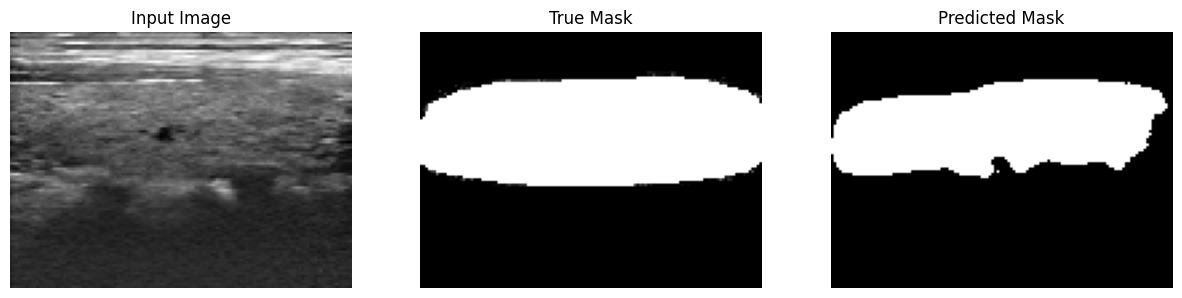

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 162ms/step


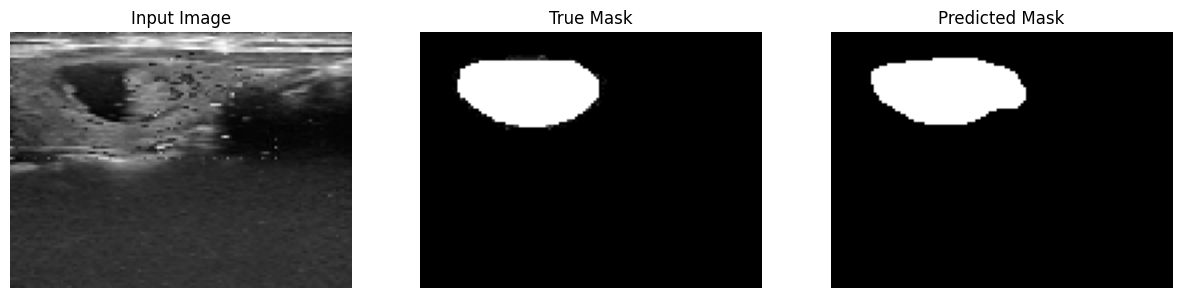

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 166ms/step


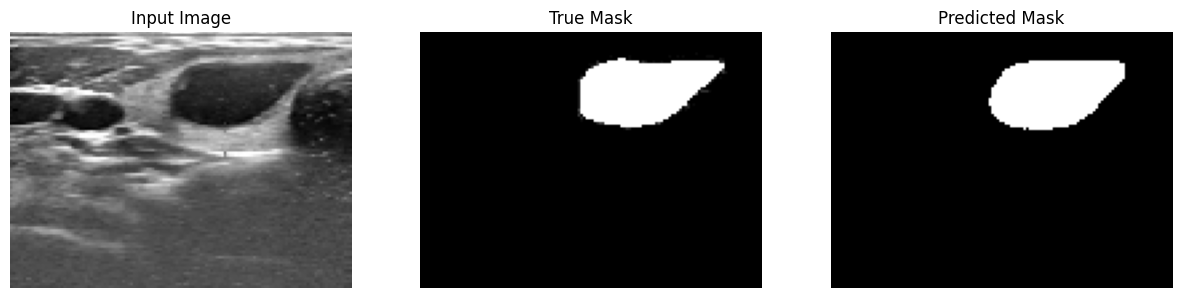

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step


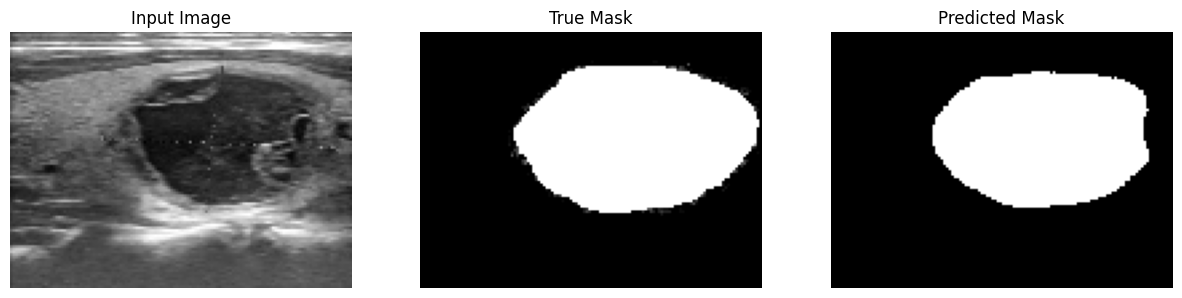

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 138ms/step


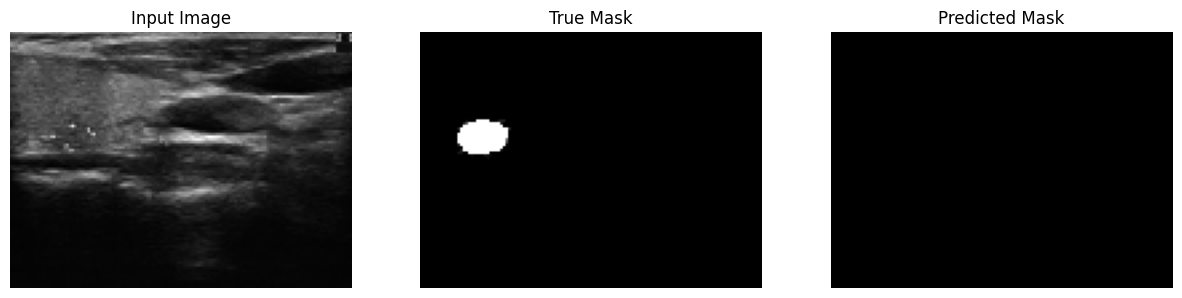

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 139ms/step


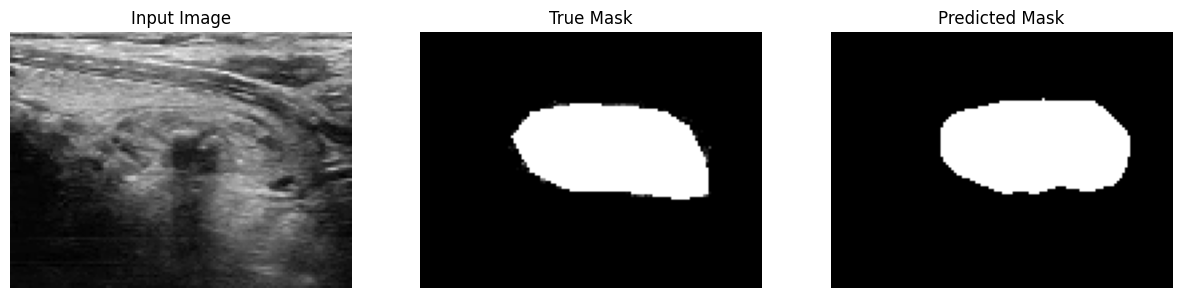

In [ ]:

show_predictions(train_dataset, 6)